In [1]:
%pip -q install "transformers==4.57.1" "accelerate==1.11.0" "librosa==0.11.0"

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.42.1 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.31.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.


## 1. Load the recordings and split by actor

The third field of each RAVDESS filename identifies the emotion. The last field identifies the actor. We rebuild the labels from the filenames so the notebook can use the WAV files directly.

| Split | Actors | Clips in the full archive |
|---|---|---:|
| Train | 01–18 | 1,080 |
| Validation | 19–20 | 120 |
| Test | 21–24 | 240 |

In [7]:
from pathlib import Path
import re
import shutil
import tempfile
from zipfile import ZipFile

from google.colab import drive
import pandas as pd

drive.mount("/content/drive")
ZIP_PATH = Path("/content/drive/MyDrive/Audio_Speech_Actors_01-24 (1).zip")

if not ZIP_PATH.is_file():
    raise FileNotFoundError(f"Upload the WAV archive to My Drive or update ZIP_PATH: {ZIP_PATH}")

EMOTIONS = ("neutral", "calm", "happy", "sad", "angry", "fearful", "disgust", "surprised")
LABEL_TO_ID = {name: idx for idx, name in enumerate(EMOTIONS)}
ID_TO_LABEL = dict(enumerate(EMOTIONS))
LABEL_IDS = list(ID_TO_LABEL)
speech_filename = re.compile(r"03-01-(0[1-8])-\d{2}-\d{2}-\d{2}-(\d{2})\.wav", re.I)

audio_dir = Path(tempfile.mkdtemp(prefix="ravdess-", dir="/content"))
rows = []

with ZipFile(ZIP_PATH) as archive:
    for member in sorted(archive.infolist(), key=lambda item: item.filename):
        name = Path(member.filename.replace("\\", "/")).name
        match = speech_filename.fullmatch(name)
        if match is None:
            continue

        label_id = int(match[1]) - 1
        actor = int(match[2])
        path = audio_dir / name
        if path.exists():
            raise ValueError(f"Duplicate recording in the archive: {name}")

        with archive.open(member) as source, path.open("wb") as target:
            shutil.copyfileobj(source, target)

        rows.append((str(path), actor, EMOTIONS[label_id], label_id))

df = pd.DataFrame(rows, columns=["filepath", "actor", "emotion", "label_id"])
if set(df["actor"]) != set(range(1, 25)):
    raise ValueError("Expected speech WAV files for actors 01–24. Check the contents of your ZIP.")

train_df = df[df["actor"].between(1, 18)].reset_index(drop=True)
val_df = df[df["actor"].between(19, 20)].reset_index(drop=True)
test_df = df[df["actor"].between(21, 24)].reset_index(drop=True)

for name, split in (("train", train_df), ("validation", val_df), ("test", test_df)):
    if set(split["label_id"]) != set(LABEL_IDS):
        raise ValueError(f"The {name} split is missing emotion classes.")
    print(f"{name:10} {len(split):4} clips | actors {sorted(split['actor'].unique().tolist())}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
train      1080 clips | actors [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18]
validation  120 clips | actors [19, 20]
test        240 clips | actors [21, 22, 23, 24]


In [5]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 2. Listening to a training clip and plotting it

The mel spectrogram is for exploration. The Random Forest uses MFCCs and Wav2Vec2 uses the waveform.

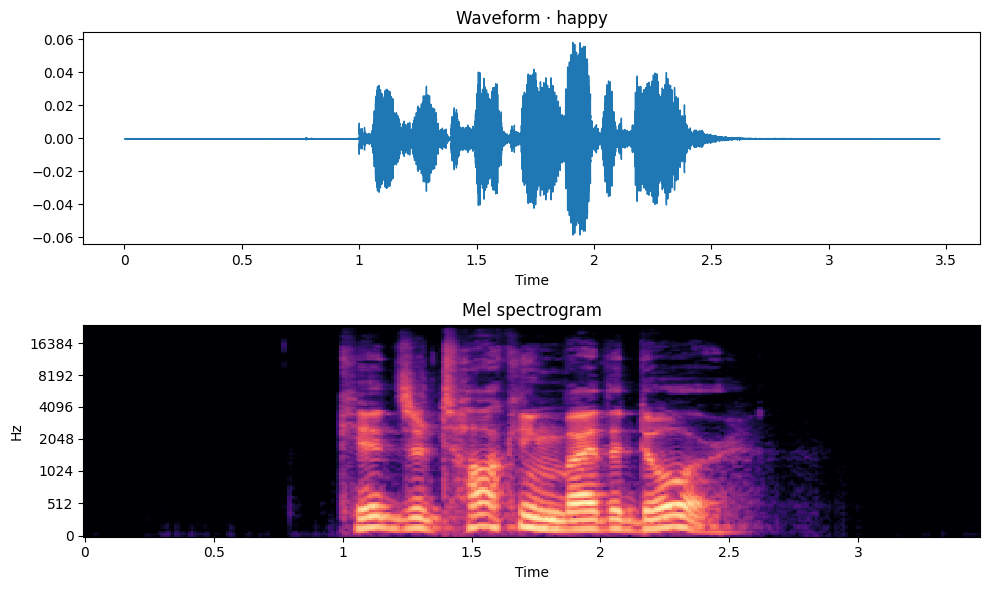

Original sample rate: 48,000 Hz


In [8]:
import librosa
import librosa.display
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Audio, display

sample = train_df.loc[train_df["emotion"].eq("happy")].iloc[0]
waveform, sample_rate = librosa.load(sample["filepath"], sr=None)
display(Audio(waveform, rate=sample_rate))

fig, axes = plt.subplots(2, 1, figsize=(10, 6))
librosa.display.waveshow(waveform, sr=sample_rate, ax=axes[0])
axes[0].set_title(f"Waveform · {sample['emotion']}")
mel = librosa.feature.melspectrogram(y=waveform, sr=sample_rate)
librosa.display.specshow(
    librosa.power_to_db(mel, ref=np.max),
    sr=sample_rate, x_axis="time", y_axis="mel", ax=axes[1],
)
axes[1].set_title("Mel spectrogram")
fig.tight_layout()
plt.show()
print(f"Original sample rate: {sample_rate:,} Hz")

## 3. Train  MFCC + Random Forest baseline


In [9]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score

TARGET_SR = 16_000
SEED = 42

def extract_mfcc(filepath):
    waveform, _ = librosa.load(filepath, sr=TARGET_SR)
    mfccs = librosa.feature.mfcc(y=waveform, sr=TARGET_SR, n_mfcc=13)
    return mfccs.mean(axis=1)

X_train = np.stack([extract_mfcc(path) for path in train_df["filepath"]])
X_val = np.stack([extract_mfcc(path) for path in val_df["filepath"]])
baseline = RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=-1)
baseline.fit(X_train, train_df["label_id"])

def scores(labels, predictions):
    return {
        "accuracy": accuracy_score(labels, predictions),
        "macro_f1": f1_score(
            labels, predictions, labels=LABEL_IDS, average="macro", zero_division=0
        ),
    }

print("Random Forest validation:", scores(val_df["label_id"], baseline.predict(X_val)))

Random Forest validation: {'accuracy': 0.39166666666666666, 'macro_f1': 0.3708058201960641}


## 4. Prepare Wav2Vec2 inputs

Resample to 16 kHz and pad or trim each clip to four seconds. Each dataset item contains a 64,000-sample waveform and an integer emotion label. The Trainer stacks the items into batches.

In [10]:
import torch
from torch.utils.data import Dataset
from transformers import (
    Trainer,
    TrainingArguments,
    Wav2Vec2FeatureExtractor,
    Wav2Vec2ForSequenceClassification,
    set_seed,
)

if not torch.cuda.is_available():
    raise RuntimeError("Select a GPU in Runtime → Change runtime type, then rerun the notebook.")
if tuple(map(int, torch.__version__.split(".")[:2])) < (2, 6):
    raise RuntimeError("Use a current Colab runtime with PyTorch 2.6 or newer to load this checkpoint.")

print("GPU:", torch.cuda.get_device_name(0))
MODEL_NAME = "facebook/wav2vec2-base"
TARGET_SAMPLES = 4 * TARGET_SR
feature_extractor = Wav2Vec2FeatureExtractor.from_pretrained(MODEL_NAME)

class EmotionDataset(Dataset):
    def __init__(self, frame):
        self.paths = frame["filepath"].tolist()
        self.labels = frame["label_id"].tolist()

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):
        waveform, _ = librosa.load(self.paths[idx], sr=TARGET_SR)
        waveform = librosa.util.fix_length(waveform, size=TARGET_SAMPLES)
        inputs = feature_extractor(
            waveform, sampling_rate=TARGET_SR, return_tensors="pt"
        )
        return {"input_values": inputs.input_values[0], "labels": self.labels[idx]}

train_dataset = EmotionDataset(train_df)
val_dataset = EmotionDataset(val_df)
test_dataset = EmotionDataset(test_df)

item = train_dataset[0]
assert item["input_values"].shape == (TARGET_SAMPLES,)
print(item["input_values"].shape, ID_TO_LABEL[item["labels"]])

GPU: Tesla T4


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


preprocessor_config.json:   0%|          | 0.00/159 [00:00<?, ?B/s]

torch.Size([64000]) neutral


## 5. Train Wav2Vec2

The emotion classification head starts with newly initialized weights. The convolutional feature encoder is frozen for this first run. The transformer and emotion head train together.

The 10-step check exercises the training pipeline. For the full run, the Trainer evaluates validation macro-F1 at the end of each epoch and reloads the best checkpoint. Macro-F1 gives each emotion equal weight.

In [13]:
SMOKE_TEST = False  # Set to False and rerun this cell for the full training run.

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    return scores(labels, np.argmax(logits, axis=1))

def train_wav2vec2(smoke_test):
    set_seed(SEED)
    model = Wav2Vec2ForSequenceClassification.from_pretrained(
        MODEL_NAME, num_labels=len(EMOTIONS), label2id=LABEL_TO_ID, id2label=ID_TO_LABEL
    )
    model.freeze_feature_encoder()

    args = TrainingArguments(
        output_dir=tempfile.mkdtemp(prefix="wav2vec2-", dir="/content"),
        per_device_train_batch_size=4,
        per_device_eval_batch_size=4,
        num_train_epochs=5,
        max_steps=10 if smoke_test else -1,
        learning_rate=3e-5,
        eval_strategy="no" if smoke_test else "epoch",
        save_strategy="no" if smoke_test else "epoch",
        load_best_model_at_end=not smoke_test,
        metric_for_best_model="macro_f1",
        greater_is_better=True,
        save_total_limit=2,
        logging_steps=5 if smoke_test else 25,
        report_to="none",
        seed=SEED,
    )

    trainer = Trainer(
        model=model,
        args=args,
        train_dataset=train_dataset,
        eval_dataset=val_dataset,
        compute_metrics=compute_metrics,
    )
    trainer.train()
    return trainer

# Release the previous model before rerunning this cell on the same GPU.
trainer = None
torch.cuda.empty_cache()
trainer = train_wav2vec2(SMOKE_TEST)

if not SMOKE_TEST:
    from datetime import datetime, timezone

    run_name = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
    results_dir = Path("/content/drive/MyDrive/speech-emotion-results") / run_name
    model_dir = results_dir / "model"
    trainer.save_model(str(model_dir))
    feature_extractor.save_pretrained(str(model_dir))
    print("Saved best validation model to", model_dir)
    print(trainer.evaluate())

/usr/local/lib/python3.13/dist-packages/transformers/configuration_utils.py:335: UserWarning: Passing `gradient_checkpointing` to a config initialization is deprecated and will be removed in v5 Transformers. Using `model.gradient_checkpointing_enable()` instead, or if you are using the `Trainer` API, pass `gradient_checkpointing=True` in your `TrainingArguments`.
  warnings.warn(
Some weights of Wav2Vec2ForSequenceClassification were not initialized from the model checkpoint at facebook/wav2vec2-base and are newly initialized: ['classifier.bias', 'classifier.weight', 'projector.bias', 'projector.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
/usr/local/lib/python3.13/dist-packages/torch/utils/checkpoint.py:242: UserWarning: None of the inputs have requires_grad=True. Gradients will be None
  check_backward_validity(args)


Epoch,Training Loss,Validation Loss,Accuracy,Macro F1
1,1.611300,1.515631,0.341667,0.238973
2,1.070300,1.132459,0.641667,0.576341
3,0.622400,0.984995,0.733333,0.726998
4,0.337500,0.988690,0.691667,0.698688
5,0.192700,1.098688,0.708333,0.706645


/usr/local/lib/python3.13/dist-packages/torch/utils/checkpoint.py:242: UserWarning: None of the inputs have requires_grad=True. Gradients will be None
  check_backward_validity(args)
/usr/local/lib/python3.13/dist-packages/torch/utils/checkpoint.py:242: UserWarning: None of the inputs have requires_grad=True. Gradients will be None
  check_backward_validity(args)
/usr/local/lib/python3.13/dist-packages/torch/utils/checkpoint.py:242: UserWarning: None of the inputs have requires_grad=True. Gradients will be None
  check_backward_validity(args)
/usr/local/lib/python3.13/dist-packages/torch/utils/checkpoint.py:242: UserWarning: None of the inputs have requires_grad=True. Gradients will be None
  check_backward_validity(args)


Saved best validation model to /content/drive/MyDrive/speech-emotion-results/20261114T164003Z/model


{'eval_loss': 0.984995424747467, 'eval_accuracy': 0.7333333333333333, 'eval_macro_f1': 0.7269977966372654, 'eval_runtime': 2.9353, 'eval_samples_per_second': 40.882, 'eval_steps_per_second': 10.22, 'epoch': 5.0}


## 6. Evaluate both models on held-out test actors



,accuracy,macro_f1
model,,
MFCC + Random Forest,0.320833,0.307932
Wav2Vec2,0.787500,0.768670


              precision    recall  f1-score   support

     neutral       0.71      0.62      0.67        16
        calm       0.70      0.94      0.80        32
       happy       0.87      0.41      0.55        32
         sad       0.59      0.53      0.56        32
       angry       0.94      1.00      0.97        32
     fearful       0.93      0.81      0.87        32
     disgust       0.88      0.94      0.91        32
   surprised       0.72      0.97      0.83        32

    accuracy                           0.79       240
   macro avg       0.79      0.78      0.77       240
weighted avg       0.80      0.79      0.78       240



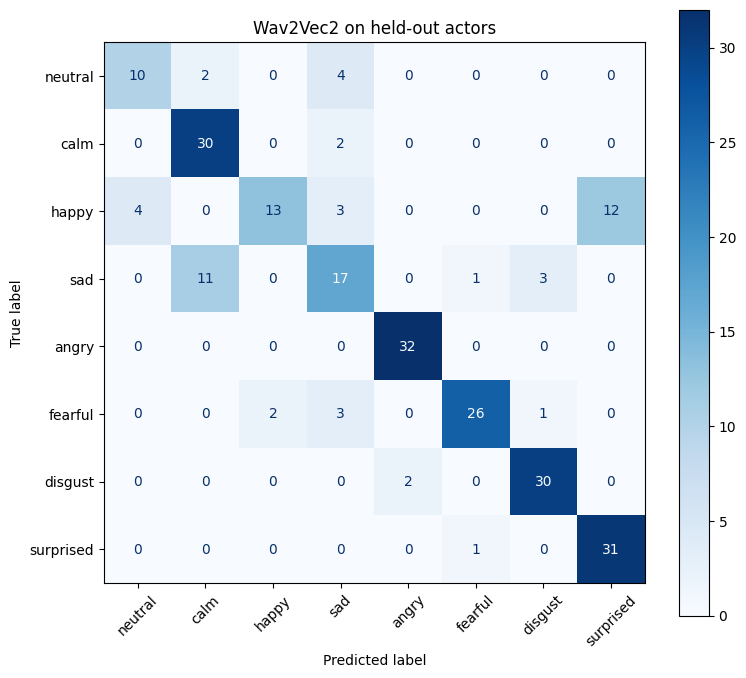

In [14]:
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

if trainer is None or trainer.args.max_steps > 0:
    raise RuntimeError("Set SMOKE_TEST = False and finish training before running this cell.")

X_test = np.stack([extract_mfcc(path) for path in test_df["filepath"]])
baseline_predictions = baseline.predict(X_test)
test_output = trainer.predict(test_dataset)
wav2vec_predictions = np.argmax(test_output.predictions, axis=1)
test_labels = test_df["label_id"]

comparison = pd.DataFrame(
    [
        {"model": "MFCC + Random Forest", **scores(test_labels, baseline_predictions)},
        {"model": "Wav2Vec2", **scores(test_labels, wav2vec_predictions)},
    ]
).set_index("model")
display(comparison)
comparison.to_csv(results_dir / "test_metrics.csv")

report = classification_report(
    test_labels, wav2vec_predictions, labels=LABEL_IDS, target_names=EMOTIONS, zero_division=0
)
print(report)
(results_dir / "wav2vec2_classification_report.txt").write_text(report, encoding="utf-8")

fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay.from_predictions(
    test_labels, wav2vec_predictions, labels=LABEL_IDS,
    display_labels=EMOTIONS, xticks_rotation=45, ax=ax, cmap="Blues",
)
ax.set_title("Wav2Vec2 on held-out actors")
fig.tight_layout()
fig.savefig(results_dir / "wav2vec2_confusion_matrix.png", dpi=150)
plt.show()

In [16]:
clip_index = 0  # Try 1, 2, 3, ... to hear other test clips.
clip = test_df.iloc[clip_index]

audio, sr = librosa.load(clip["filepath"], sr=None)
display(Audio(audio, rate=sr))

print("True emotion:", clip["emotion"])
print("Random Forest:", ID_TO_LABEL[int(baseline_predictions[clip_index])])
print("Wav2Vec2:", ID_TO_LABEL[int(wav2vec_predictions[clip_index])])

True emotion: neutral
Random Forest: sad
Wav2Vec2: neutral


In [17]:
from pathlib import Path
import shutil

import joblib
import sklearn

predictions = test_df[["actor", "emotion"]].copy()
predictions["clip"] = test_df["filepath"].map(lambda path: Path(path).name)
predictions["random_forest"] = [
    ID_TO_LABEL[int(i)] for i in baseline_predictions
]
predictions["wav2vec2"] = [
    ID_TO_LABEL[int(i)] for i in wav2vec_predictions
]

predictions.to_csv(results_dir / "test_predictions.csv", index=False)
pd.DataFrame(trainer.state.log_history).to_csv(
    results_dir / "training_history.csv", index=False
)
joblib.dump(baseline, results_dir / "random_forest.joblib")
(results_dir / "sklearn_version.txt").write_text(
    sklearn.__version__, encoding="utf-8"
)

# Save the exact recording you just played.
shutil.copyfile(clip["filepath"], results_dir / "demo_clip.wav")

print("Saved to:", results_dir)
print("Test predictions:", len(predictions))

Saved to: /content/drive/MyDrive/speech-emotion-results/20261114T164003Z
Test predictions: 240
